# GridQ: QAOA load balancing for a rural microgrid
**QFF 2026 Quantum for Humanity: Climate track.** Live demo notebook. All data is synthetic.

At 19:00 the sun has set, but demand peaks: lights, the clinic's vaccine fridge, the water pump.
The village operator must decide **which flexible assets to switch on** (batteries, a diesel genset,
demand-response contracts) to cover the shortfall **at the lowest cost without overloading shared lines**.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx
from gridq import *
from gridq.qaoa import depth_sweep
grid = make_microgrid(n=8, density=0.4, seed=0)
pd.DataFrame({"site": grid.kinds, "asset": grid.assets, "kW": grid.power, "cost ₹": grid.cost,
              "critical": grid.priority.astype(bool)})

,site,asset,kW,cost ₹,critical
0,household,diesel,5.6,139.2,False
1,household,diesel,4.5,119.6,False
2,school,battery,4.2,20.9,False
3,clinic,demand_response,2.1,26.0,True
4,household,demand_response,1.6,18.2,False
5,cold_store,diesel,5.9,148.3,True
6,water_pump,diesel,7.6,221.3,True
7,household,diesel,7.7,183.4,False


Deficit to cover: 17.6 kW  |  lines: 11  |  density 0.39


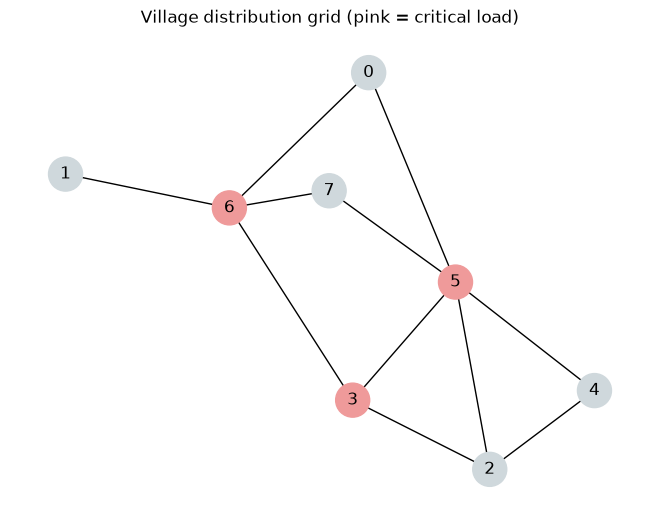

In [2]:
print(f"Deficit to cover: {grid.deficit} kW  |  lines: {grid.graph.number_of_edges()}  |  density {grid.density:.2f}")
pos = nx.spring_layout(grid.graph, seed=1)
nx.draw(grid.graph, pos, with_labels=True, node_color=["#ef9a9a" if p else "#cfd8dc" for p in grid.priority], node_size=600)
plt.title("Village distribution grid (pink = critical load)"); plt.show()

## 1. QUBO formulation
$$H(x)=A\Big(\sum_i \tfrac{p_i}{D}x_i-1\Big)^2+\sum_i \tilde c_i x_i + B\sum_{(i,j)\in E} w_{ij}x_ix_j - C\sum_i r_i x_i$$
balance · cost · line overload ($w_{ij}>0$ only when $p_i+p_j$ exceeds line capacity) · critical-load bonus. One qubit per asset.

In [3]:
qubo = build_qubo(grid)
op, offset, scale = qubo.to_ising()
print(f"{qubo.n} qubits, {len(op)} Pauli terms")
print(qubo.to_quadratic_program().prettyprint()[:800])

8 qubits, 36 Pauli terms
Problem name: microgrid_dispatch

Minimize
  3.254132231404958*x0*x1 + 3.0371900826446274*x0*x2 + 1.5185950413223137*x0*x3
  + 1.1570247933884297*x0*x4 + 4.454028925619833*x0*x5 + 5.82936776859504*x0*x6
  + 5.5681818181818175*x0*x7 + 2.4405991735537187*x1*x2
  + 1.2202995867768593*x1*x3 + 0.9297520661157025*x1*x4
  + 3.4284607438016526*x1*x5 + 4.619122314049586*x1*x6 + 4.474431818181818*x1*x7
  + 1.1389462809917354*x2*x3 + 0.8677685950413223*x2*x4
  + 3.2850966942148756*x2*x5 + 4.12190082644628*x2*x6 + 4.176136363636363*x2*x7
  + 0.43388429752066116*x3*x4 + 1.6147483471074378*x3*x5
  + 2.19785041322314*x3*x6 + 2.0880681818181817*x3*x7 + 1.22240826446281*x4*x5
  + 1.5702479338842974*x4*x6 + 1.590909090909091*x4*x7 + 5.790289256198346*x5*x6
  + 6.189177272727273*x5*x7 + 7.94491818181818*x6*x


## 2. Classical baselines (the benchmark to beat)

In [4]:
exact = constrained_optimum(qubo)
rows = []
for name, x in [("exact (brute force)", exact.x), ("operator rule: cheapest first", greedy_operator(qubo).x),
                ("greedy descent", greedy_descent(qubo).x), ("simulated annealing", simulated_annealing(qubo).x),
                ("random sampling, 256 shots", random_sampling(qubo, 256).x)]:
    x = repair(grid, x); m = dispatch_metrics(grid, x)
    rows.append({"solver": name, "optimal": bool((x == exact.x).all()), **m, "saved vs diesel-first %": cost_saved_pct(grid, x)})
pd.DataFrame(rows)

,solver,optimal,supplied_kw,deficit_kw,demand_met_pct,surplus_kw,cost_inr,assets_on,critical_assets_on,overloaded_lines,saved vs diesel-first %
0,exact (brute force),True,18.0,17.6,100.0,0.4,323.9,5,1,0,33.8
1,operator rule: cheapest first,False,19.6,17.6,100.0,2.0,369.5,4,1,0,24.5
2,greedy descent,False,19.5,17.6,100.0,1.9,425.6,3,1,1,13.0
3,simulated annealing,False,18.0,17.6,100.0,0.4,342.1,4,0,0,30.1
4,"random sampling, 256 shots",True,18.0,17.6,100.0,0.4,323.9,5,1,0,33.8


## 3. QAOA: train noise-free, sample on the Sampler primitive

In [5]:
res = solve_qaoa(qubo, reps=3, shots=1024)
x = res.repaired_x
print("dispatch:", x, "optimal:", bool((x == exact.x).all()))
print(f"P(optimal) = {res.p_optimal:.3f}  =  {res.enrichment:.1f}× random guessing")
print("transpiled circuit:", res.circuit_stats)
dispatch_metrics(grid, x)

dispatch: [1 1 1 1 1 0 0 0] optimal: True
P(optimal) = 0.021  =  5.2× random guessing
transpiled circuit: {'depth': 106, 'two_qubit_gates': 168, 'two_qubit_depth': 58, 'num_qubits': 8}


{'supplied_kw': 18.0,
 'deficit_kw': 17.6,
 'demand_met_pct': 100.0,
 'surplus_kw': 0.4,
 'cost_inr': 323.9,
 'assets_on': 5,
 'critical_assets_on': 1,
 'overloaded_lines': 0}

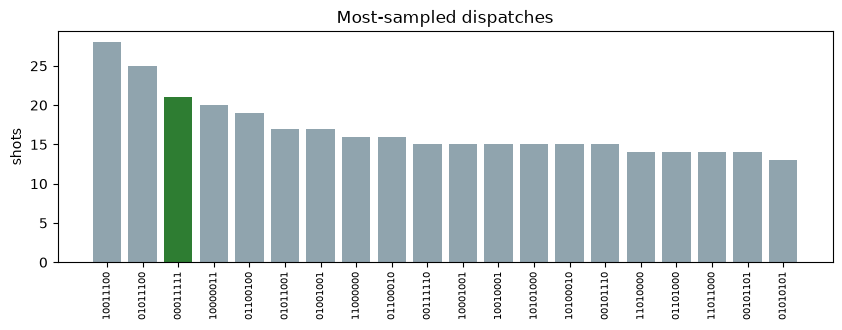

In [6]:
top = sorted(res.counts.items(), key=lambda kv: -kv[1])[:20]
e_opt = qubo.energy(exact.x)
colors = ["#2e7d32" if np.isclose(qubo.energy(np.array([int(c) for c in reversed(k)])), qubo.energy(constrained_optimum(qubo).x)) else "#90a4ae" for k, _ in top]
plt.figure(figsize=(10, 3)); plt.bar([k for k, _ in top], [v for _, v in top], color=colors)
plt.xticks(rotation=90, fontsize=7); plt.ylabel("shots"); plt.title("Most-sampled dispatches"); plt.show()

## 4. Depth sweep: does more circuit help? (INTERP warm start)

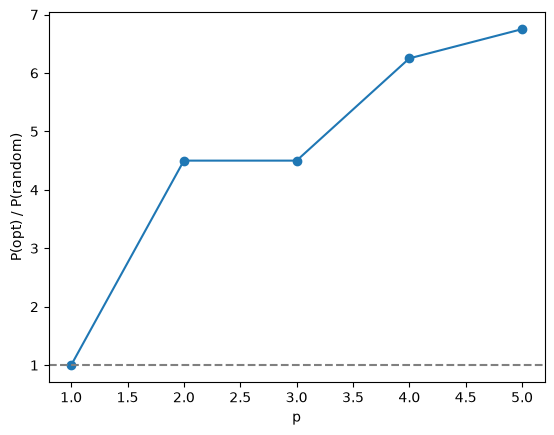

,p,enrichment,2q depth
0,1,1.00,26
1,2,4.50,42
2,3,4.50,58
3,4,6.25,74
4,5,6.75,90


In [7]:
sweep = depth_sweep(qubo, max_reps=5, shots=1024)
df = pd.DataFrame([{"p": r.reps, "enrichment": r.enrichment, "2q depth": r.circuit_stats["two_qubit_depth"]} for r in sweep])
ax = df.plot(x="p", y="enrichment", marker="o", legend=False); ax.axhline(1, ls="--", c="grey")
ax.set_ylabel("P(opt) / P(random)"); plt.show(); df

## 5. Noise: the same circuit on a snapshot of a real IBM Heron device

In [8]:
from gridq.hardware import fake_backend, noisy_sampler, backend_pass_manager
fb = fake_backend()
noisy = solve_qaoa(qubo, reps=3, shots=1024, sampler=noisy_sampler(fb), pass_manager=backend_pass_manager(fb))
pd.DataFrame([{"backend": "ideal", "enrichment": res.enrichment, **res.circuit_stats},
              {"backend": fb.name + " (noise model)", "enrichment": noisy.enrichment, **noisy.circuit_stats}])

,backend,enrichment,depth,two_qubit_gates,two_qubit_depth,num_qubits
0,ideal,5.25,106,168,58,8
1,fake_fez (noise model),2.25,563,313,185,156


## 6. Honest take
* At village scale (≤ 12 nodes) brute force is **exact and takes under a millisecond**. Classical wins today.
* QAOA concentrates probability on the optimal dispatch (several× over random), and the gain grows with depth *p*, but noise erodes it as 2-qubit depth grows.
* After the same feasibility repair, random sampling with the same shot budget also finds the optimum at this size. The quantum signal is real, but it doesn't change the decision yet.
* Any practical value would have to come from **district-scale** grids (hundreds of assets) on error-mitigated or fault-tolerant hardware.

Full benchmarks: `python experiments/run_benchmarks.py` → `results/`.